# Question 10: does climate risk explain the 2024-2026 declines in Tampa and Orlando?

The forecast missed the Florida decline, and the model card blamed missing drivers such as insurance. This tests the
one risk measure the data now has: FEMA's National Risk Index (v1.20, December 2025), as the expected annual loss of
building value from natural hazards over the value of the buildings. Three rates per ZIP, each a `res_ratio`-weighted
average over the ZIP's counties: all hazards, hurricanes, and coastal plus inland flooding. Source: `gold.dim_zip`
(risk) and `gold.mart_zip_month` (Zillow ZHVI). The change runs from the 2024 average to the latest 12 months.

Caveats: the index is by county, so inside Tampa and Orlando it varies only between their 8 counties, not between a
waterfront ZIP and an inland one in the same county. It measures physical risk, not insurance premiums. Florida
premiums rose statewide for reasons a county risk score does not capture (litigation, reinsurance costs), so a null
here does not rule out insurance. The 2025 release postdates the period, which is fine for a description but would
leak into a forecast feature.

In [1]:
import common as c
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

In [2]:
z = c.q(
    """
    select d.zip, d.cbsa_code, d.county_fips, d.building_loss_rate, d.hurricane_loss_rate, d.flood_loss_rate,
        avg(m.zhvi_usd) filter (year(m.month) = 2024) v0,
        avg(m.zhvi_usd) filter (m.month > $latest - interval 12 month and m.month <= $latest) v1
    from gold.dim_zip d join gold.mart_zip_month m using (zip, cbsa_code)
    where d.building_loss_rate is not null
    group by all having v0 is not null and v1 is not null
    """,
    {"latest": c.LATEST},
)
z["change"] = z.v1 / z.v0 - 1
z["metro"] = z.cbsa_code.map(c.METRO)
RATES = {
    "building_loss_rate": "All hazards",
    "hurricane_loss_rate": "Hurricane",
    "flood_loss_rate": "Flooding",
}
by = z.groupby("metro")[["change", *RATES]].median().sort_values("change")
by

,change,building_loss_rate,hurricane_loss_rate,flood_loss_rate
metro,,,,
Austin,-0.073,1.213e-03,7.103e-06,8.380e-04
Tampa,-0.070,1.685e-03,6.981e-04,6.836e-04
Dallas-Fort Worth,-0.045,1.295e-03,1.442e-06,6.743e-04
Orlando,-0.045,1.399e-03,2.869e-04,7.004e-04
Phoenix,-0.036,1.578e-03,8.201e-09,1.294e-03
Denver,-0.036,1.564e-03,0.000e+00,6.403e-04
Atlanta,-0.021,9.863e-04,4.719e-06,6.703e-04
Raleigh,-0.012,1.210e-03,4.729e-05,9.097e-04
Charlotte,0.001,1.246e-03,1.634e-05,8.816e-04


In [3]:
# Pearson r between the value change and each loss rate: across all ZIPs, within metros (each metro's mean removed),
# and within Tampa and Orlando only; plus Spearman across the 11 metro medians
fl = z.metro.isin(["Tampa", "Orlando"])


def within(d, col):
    dm = d[[col, "change"]] - d.groupby("metro")[[col, "change"]].transform("mean")
    return np.corrcoef(dm[col], dm.change)[0, 1]


r = pd.DataFrame(
    {
        label: {
            "all ZIPs": np.corrcoef(z[col], z.change)[0, 1],
            "within metros": within(z, col),
            "within Tampa and Orlando": within(z[fl], col),
            "metro medians (Spearman)": by[col].corr(by.change, method="spearman"),
        }
        for col, label in RATES.items()
    }
)
print(
    f"{z[fl].county_fips.nunique()} primary counties in Tampa and Orlando; {len(z)} ZIPs in all"
)
r.round(2)

8 primary counties in Tampa and Orlando; 1436 ZIPs in all


,All hazards,Hurricane,Flooding
all ZIPs,0.13,-0.31,0.15
within metros,0.05,0.12,0.05
within Tampa and Orlando,0.12,0.36,-0.00
metro medians (Spearman),0.05,-0.39,0.34


In [4]:
# the within-Florida correlation rests on 8 counties: by county, then without Pinellas and per metro
names = c.q("select county_fips, county_name from gold.dim_county")
fz = z[fl].merge(names, on="county_fips")
counties = (
    fz.groupby(["metro", "county_name"])
    .agg(
        zips=("zip", "size"),
        median_change=("change", "median"),
        hurricane_loss_rate=("hurricane_loss_rate", "median"),
    )
    .sort_values("median_change")
)
no_pinellas = within(fz[fz.county_name != "Pinellas County"], "hurricane_loss_rate")
tampa_r = within(fz[fz.metro == "Tampa"], "hurricane_loss_rate")
orlando_r = within(fz[fz.metro == "Orlando"], "hurricane_loss_rate")
print(
    f"hurricane r: without Pinellas {no_pinellas:+.2f}, Tampa alone {tampa_r:+.2f}, Orlando alone {orlando_r:+.2f}"
)
counties

hurricane r: without Pinellas -0.09, Tampa alone +0.51, Orlando alone -0.11


zips  median_change  hurricane_loss_rate
metro   county_name                                                  
Tampa   Pinellas County        47         -0.094            6.299e-04
        Pasco County           23         -0.070            7.127e-04
Orlando Osceola County         12         -0.059            2.907e-04
Tampa   Hernando County        10         -0.052            7.777e-04
        Hillsborough County    49         -0.051            6.981e-04
Orlando Orange County          42         -0.044            2.869e-04
        Seminole County        13         -0.042            2.874e-04
        Lake County            23         -0.038            2.705e-04

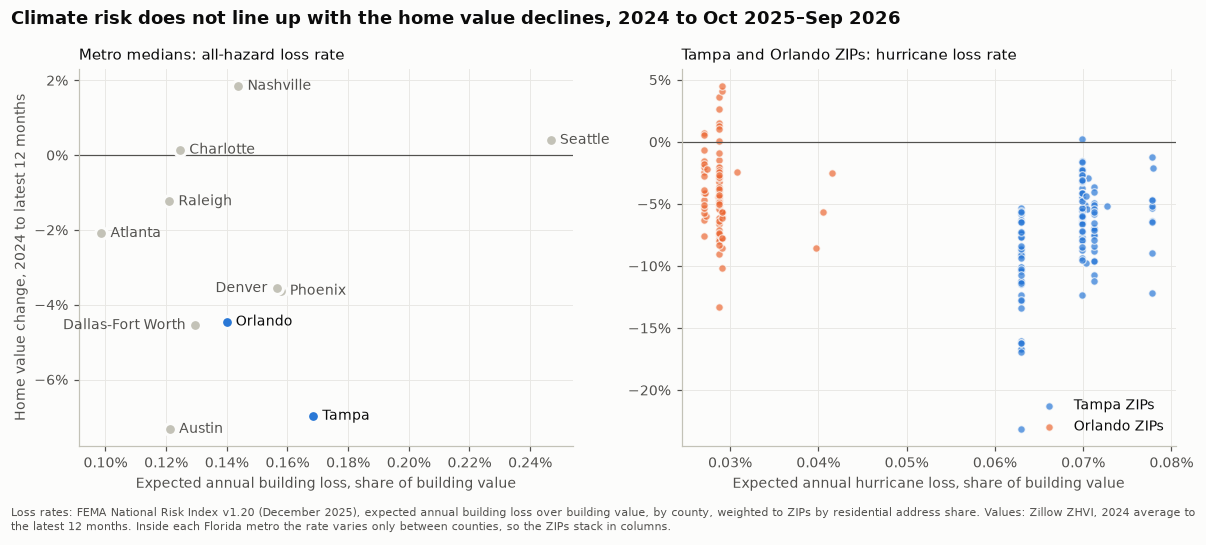

In [5]:
fig, (a, b) = c.plt.subplots(1, 2, figsize=(11, 4.6))
for m, row in by.iterrows():
    florida = m in ("Tampa", "Orlando")
    a.scatter(
        row.building_loss_rate,
        row.change,
        s=60,
        color=c.BLUE if florida else c.MUTED,
        edgecolor=c.SURFACE,
        linewidth=2,
        zorder=3,
    )
    left = m in ("Denver", "Dallas-Fort Worth")  # neighbors on the right would collide
    a.annotate(
        m,
        (row.building_loss_rate, row.change),
        xytext=(-6 if left else 6, 0),
        textcoords="offset points",
        va="center",
        ha="right" if left else "left",
        color=c.INK if florida else c.INK2,
    )
a.axhline(0, color=c.INK2, lw=0.8)
a.set_title("Metro medians: all-hazard loss rate")
a.set_xlabel("Expected annual building loss, share of building value")
a.set_ylabel("Home value change, 2024 to latest 12 months")
for m, col in (("Tampa", c.BLUE), ("Orlando", c.ORANGE)):
    d = z[z.metro == m]
    b.scatter(
        d.hurricane_loss_rate,
        d.change,
        s=24,
        color=col,
        alpha=0.7,
        edgecolor=c.SURFACE,
        linewidth=0.8,
        label=f"{m} ZIPs",
    )
b.axhline(0, color=c.INK2, lw=0.8)
b.set_title("Tampa and Orlando ZIPs: hurricane loss rate")
b.set_xlabel("Expected annual hurricane loss, share of building value")
b.legend(frameon=False, loc="lower right")
for ax in (a, b):
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=2))
c.save(
    fig,
    "q10_climate_risk",
    f"Climate risk does not line up with the home value declines, 2024 to {c.LATEST_12M}",
    "Loss rates: FEMA National Risk Index v1.20 (December 2025), expected annual building loss over building value, "
    "by county, weighted to ZIPs by residential address share. Values: Zillow ZHVI, 2024 average to the latest 12 "
    "months. Inside each Florida metro the rate varies only between counties, so the ZIPs stack in columns.",
)

## Answer

In [6]:
print(
    f"Median change from the 2024 average: {by.change.min():+.1%} ({by.change.idxmin()}) to "
    f"{by.change.max():+.1%} ({by.change.idxmax()}); Tampa {by.change['Tampa']:+.1%}, Orlando {by.change['Orlando']:+.1%}."
)
print(
    f"Hurricane loss rate: Tampa {by.hurricane_loss_rate['Tampa']:.3%} and Orlando {by.hurricane_loss_rate['Orlando']:.3%} "
    f"a year, against at most {by.drop(['Tampa', 'Orlando']).hurricane_loss_rate.max():.3%} elsewhere."
)
print(
    "Correlation of the change with the loss rate within Tampa and Orlando: "
    + ", ".join(
        f"{k.lower()} {v:+.2f}" for k, v in r.loc["within Tampa and Orlando"].items()
    )
    + "; within all metros: "
    + ", ".join(f"{k.lower()} {v:+.2f}" for k, v in r.loc["within metros"].items())
    + f". Hurricane without Pinellas: {no_pinellas:+.2f}."
)
p = counties.loc[("Tampa", "Pinellas County")]
print(
    f"Pinellas: median {p.median_change:+.1%}, hurricane loss rate {p.hurricane_loss_rate:.3%}, the lowest in Tampa."
)

Median change from the 2024 average: -7.3% (Austin) to +1.9% (Nashville); Tampa -7.0%, Orlando -4.5%.
Hurricane loss rate: Tampa 0.070% and Orlando 0.029% a year, against at most 0.005% elsewhere.
Correlation of the change with the loss rate within Tampa and Orlando: all hazards +0.12, hurricane +0.36, flooding -0.00; within all metros: all hazards +0.05, hurricane +0.12, flooding +0.05. Hurricane without Pinellas: -0.09.
Pinellas: median -9.4%, hurricane loss rate 0.063%, the lowest in Tampa.
